In [1]:
# Alex Netzley
# 2/26/2024

import os
import csv
import argparse
from multiprocessing import Pool, cpu_count
import importlib
from importlib import reload

import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import custom_object_scope
from tensorflow import keras
from tensorflow.keras.optimizers.schedules import LearningRateSchedule

import sys
sys.path.append("..") 

# Loading In Model
from models.model_utils import CosineDecay, ScalarAttention, CrossModalAttention, TemporalAttention 
from models.models import get_model_instance

# Packages for Base-Pair Kernel Visualization
import matplotlib.pyplot as plt
import numpy as np

# Packages for Motif Plots for Base-Pair Kernels
import matplotlib as mpl
from matplotlib.text import TextPath
from matplotlib.patches import PathPatch
from matplotlib.font_manager import FontProperties
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Packages for SHAP
import shap
import pickle
from preprocessing.generate_tf_splits import *
from preprocessing.compile_sample_data import *
from interpretation_utils import *

#model_path = "/fh/fast/ha_g/user/rpatton/TritonCNN/TritonCNNv3/results_holdout/UW-WGS_data/model.h5"
#model_path = "/fh/fast/ha_g/user/rpatton/TritonCNN/TritonCNNv3/results_holdout/UW-WGS_data/best_model.h5"
#best_model = tf.keras.models.load_model(model_path, custom_objects={'CosineDecay': CosineDecay, 'ScalarAttention': ScalarAttention, 'CrossModalAttention': CrossModalAttention, 'TemporalAttention': TemporalAttention})
# print(best_model.summary())

2024-05-15 10:03:45.008744: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


### Reloading

In [11]:
import interpretation_utils
reload(interpretation_utils)
from interpretation_utils import *

Model Loading

In [2]:
#model_path = "/fh/fast/ha_g/user/rpatton/TritonCNN/TritonCNNv3/results_holdout/UW-WGS_data/model.h5"
#model_path = "/fh/fast/ha_g/user/rpatton/TritonCNN/TritonCNNv3/results_holdout/UW-WGS_data/best_model.h5"
model_path = os.path.join(os.pardir, 'final_models', 'TPU-0x_model.h5')
best_model = tf.keras.models.load_model(model_path, custom_objects={'CosineDecay': CosineDecay, 'ScalarAttention': ScalarAttention, 'CrossModalAttention': CrossModalAttention, 'TemporalAttention': TemporalAttention})
print(best_model.summary())

2024-05-15 10:06:37.843641: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-05-15 10:06:41.146722: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1613] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10534 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1080 Ti, pci bus id: 0000:5e:00.0, compute capability: 6.1


Model: "BioCNN"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 TSS_image (InputLayer)         [(None, 2000, 11)]   0           []                               
                                                                                                  
 tf.__operators__.getitem_16 (S  (None, 2000, 4)     0           ['TSS_image[0][0]']              
 licingOpLambda)                                                                                  
                                                                                                  
 tf.compat.v1.transpose_1 (TFOp  (None, 4, 2000)     0           ['tf.__operators__.getitem_16[0][
 Lambda)                                                         0]']                             
                                                                                             

In [ ]:
# # Load in the Model
# model_weights_path = os.path.join(os.pardir, 'final_models', 'TPU-0x_weights.hdf5')
# #model_path = "/fh/fast/ha_g/user/anetzley/final_models/penultimate_weights.hdf5"
# #model_path = "../final_models/penultimate_MSE_weights.hdf5"
# best_model = load_best_model(model_weights_path)
# #best_model.summary()

Data Loading

In [6]:

#Optional origin filepaths
#filepath = '/fh/fast/ha_g/user/rpatton/TritonCNN/TritonCNNv3/data/validation_10.0x/LuCaP_136.tfrecord'
filepath = "/fh/fast/ha_g/user/rpatton/TritonCNN/Proteus/data/composite_training/AllSamples_0x_0CPM.tfrecord"

#Optional load filepaths
save_filepath = '/fh/fast/ha_g/user/anetzley/data_for_shap/full_dataset/input_data_CPM.npz'

input_data = get_data(save_filepath, regenerate_data=False, regenerate_num_samples=None, save_filepath=save_filepath)


Gene Subsetting

In [5]:
#Gene Subsetting origin tf.record filepath
#filepath = '/fh/fast/ha_g/user/rpatton/TritonCNN/TritonCNNv3/data/TissueHO-SCLC_0x/combined_fold-1.tfrecord' #WE USE THIS FOR GENE SUBSETTING
#gene_list_down_path = "/fh/fast/ha_g/user/rpatton/TritonCNN/RNA-Seq/LuCaPvsGTEx_down-regulated.txt"
#gene_list_up_path = "/fh/fast/ha_g/user/rpatton/TritonCNN/RNA-Seq/LuCaPvsGTEx_up-regulated.txt"

#Gene Subsetting load filepaths
filepath_up = '/fh/fast/ha_g/user/anetzley/data_for_shap/Lucap_vs_GTX_up/input_data.npz'
filepath_down = '/fh/fast/ha_g/user/anetzley/data_for_shap/Lucap_vs_GTX_down/input_data.npz'

input_lucap_up = get_gene_subset_data(filepath_up, gene_list_filepath=None, regenerate_data=False, save_filepath=None)
input_lucap_down = get_gene_subset_data(filepath_down, gene_list_filepath=None, regenerate_data=False, save_filepath=None)


In [ ]:
input_data_background_up = subsample(input_lucap_up, sample_size = 100)
input_data_test_up = subsample(input_lucap_up, sample_size = 100)
input_data_single_up = subsample(input_lucap_up, sample_size = 1)
input_data_background_down = subsample(input_lucap_down, sample_size = 100)
input_data_test_down = subsample(input_lucap_down, sample_size = 100)
input_data_single_down = subsample(input_lucap_down, sample_size = 1)

plot_gene_subset_predicted_expression(input_data_test_up, input_data_test_down, best_model)

In [18]:
#input_AR = get_gene_subset_data(filepath_up, gene_list_filepath='/fh/fast/ha_g/user/anetzley/data_for_shap/AR/ar_gene.txt', regenerate_data=True, save_filepath='/fh/fast/ha_g/user/anetzley/data_for_shap/AR/')
#input_AR = get_gene_subset_data('/fh/fast/ha_g/user/rpatton/TritonCNN/TritonCNNv3/data/TissueHO-SCLC_0x/combined_fold-1.tfrecord', gene_list_filepath=['AR'], regenerate_data=True, save_filepath='/fh/fast/ha_g/user/anetzley/data_for_shap/AR_CPM/ar.npz')

#Generated Data
#input_AR = get_gene_subset_data("/fh/fast/ha_g/user/rpatton/TritonCNN/Proteus/data/composite_training/AllSamples_0x_0CPM.tfrecord", gene_list_filepath=['AR'], regenerate_data=True, save_filepath='/fh/fast/ha_g/user/anetzley/data_for_shap/AR_CPM/ar.npz')

# Load Previously generated Data
input_AR = get_gene_subset_data('/fh/fast/ha_g/user/anetzley/data_for_shap/AR/ar_cpm.npz', gene_list_filepath=['AR'], regenerate_data=False)

### Kernel Visualization

This function performs the visualization of kernels at different points throughout the model, including:

1. Plotting Nucleotide Convolutional Filters
2. Plotting Nucleotide Convolutional Filter Motif Plots
3. Plotting the signal combination Conv3d Filters (8)
4. Plotting the summed signal combination Conv3d Filters

Optionally, you can pass in a folder location to save the figures


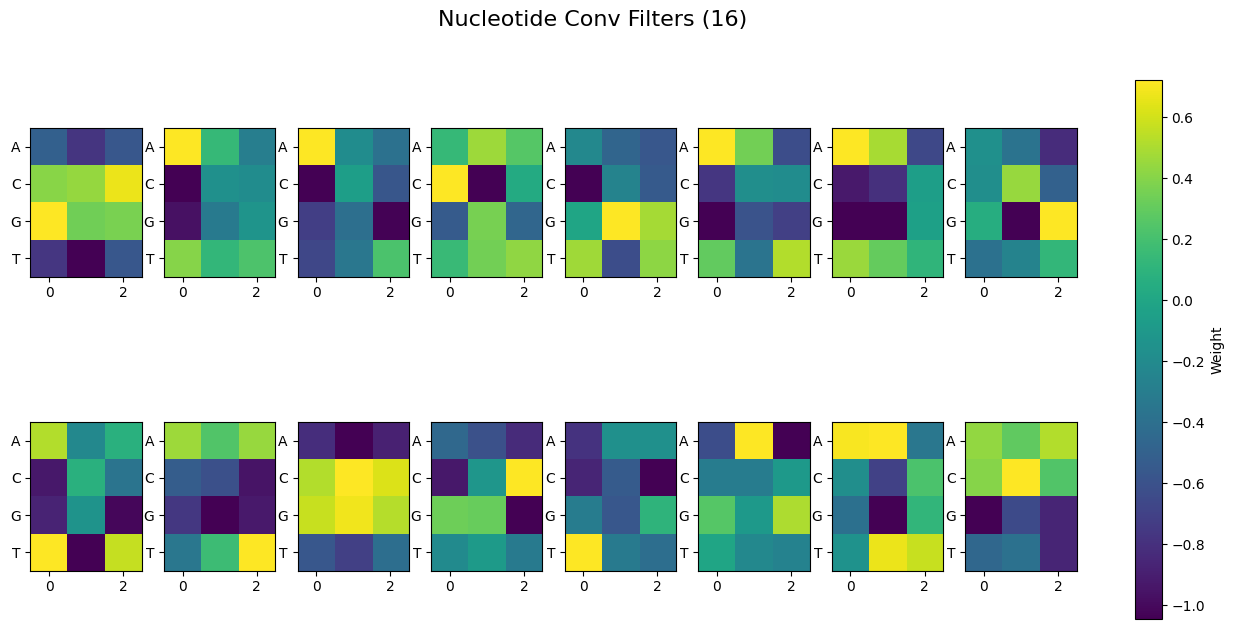

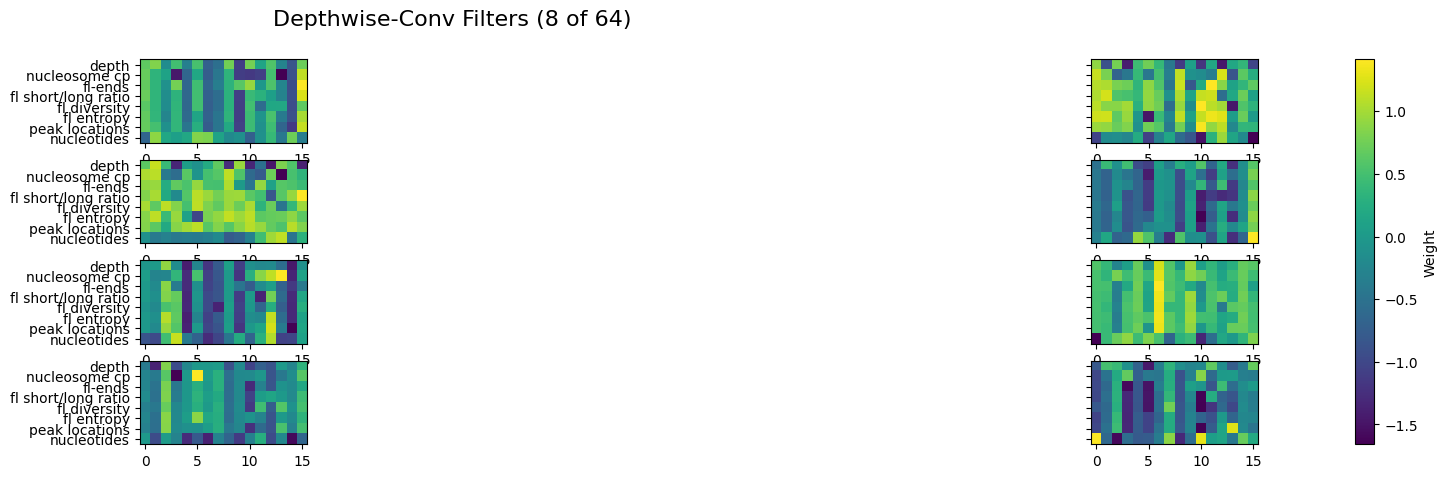

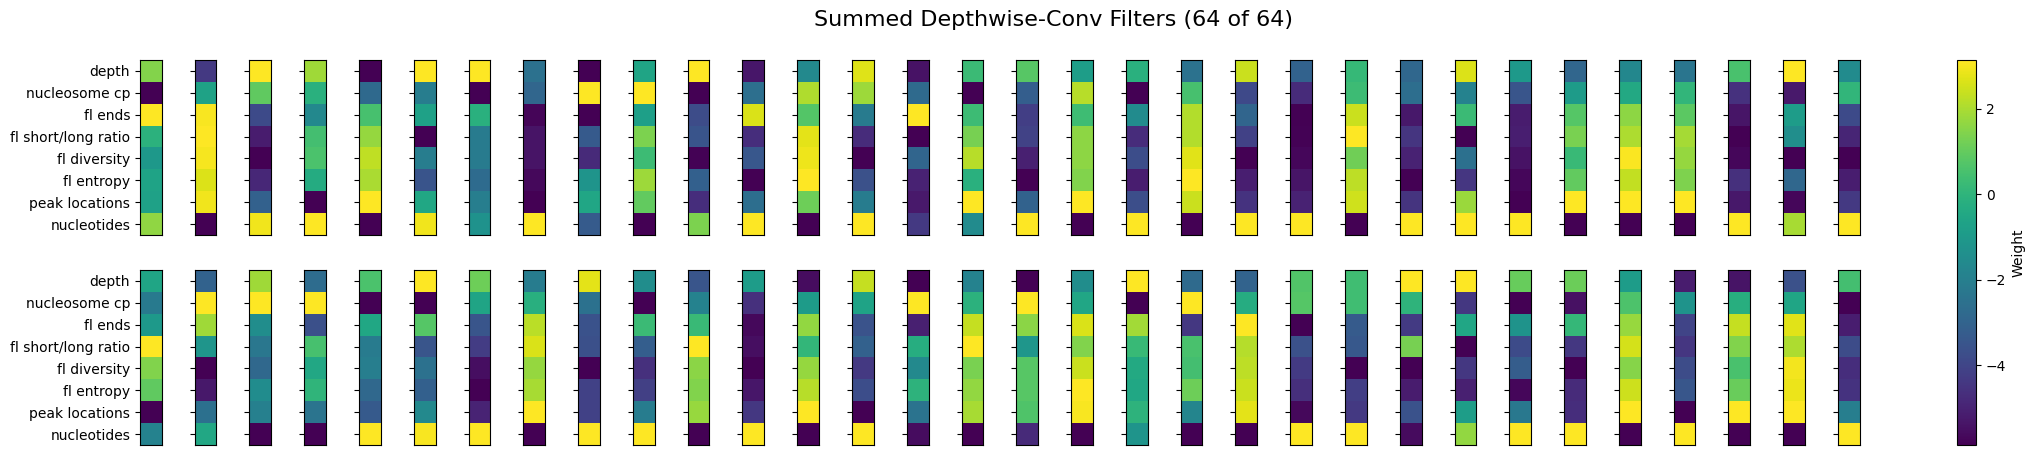

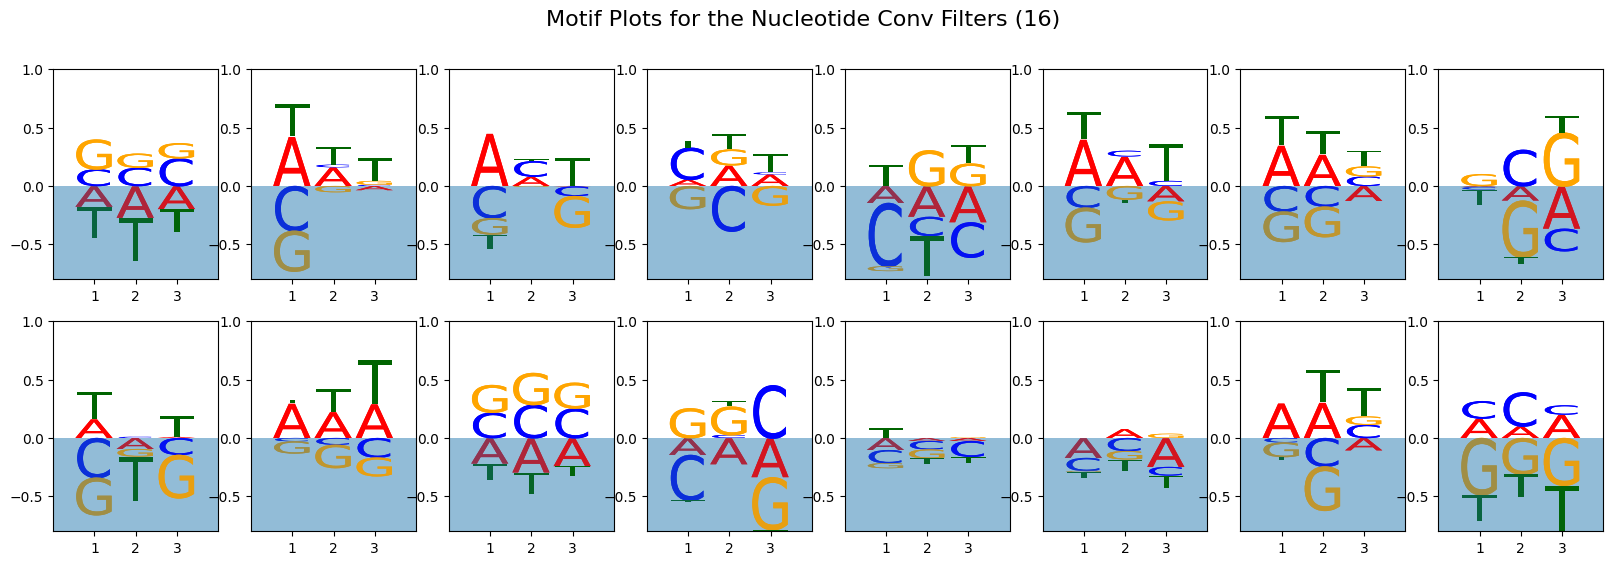

In [12]:
save_filepath = '/fh/fast/ha_g/user/anetzley/interpretation/interpretation_results'
kernel_visualization(best_model)#, save_filepath)

### Shapley Additive Explanations

This function performs SHAP analysis on a specified test and background dataset. Additionally, we visualize the following:

1. Plot mean abs SHAP Values for the TSS Images
2. Plot mean abs SHAP Values for the TSS Images with the Nucleotides summed
3. Plot mean abs SHAP Values for the TSS Images with the Nucleotides summed, each signal color scaled individually
4. Plot global comparison of mean abs SHAP Values for all inputs, with the signals summed
5. Plot global comparison of mean abs SHAP Values for three scalars
6. Plot scalars with each color bar scaled locally

Optionally, you can pass in a folder location to save the figures


<Figure size 640x480 with 0 Axes>

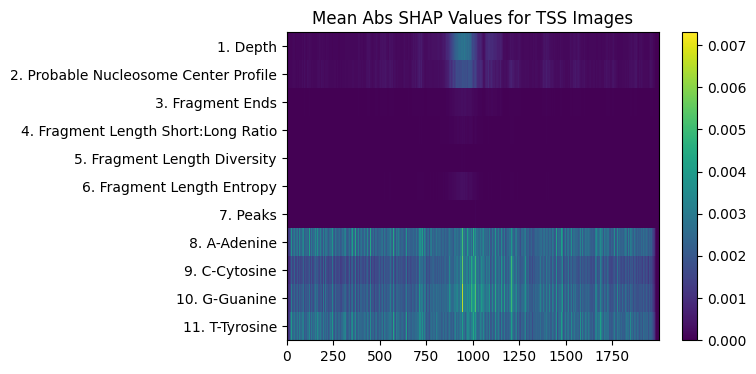

<Figure size 640x480 with 0 Axes>

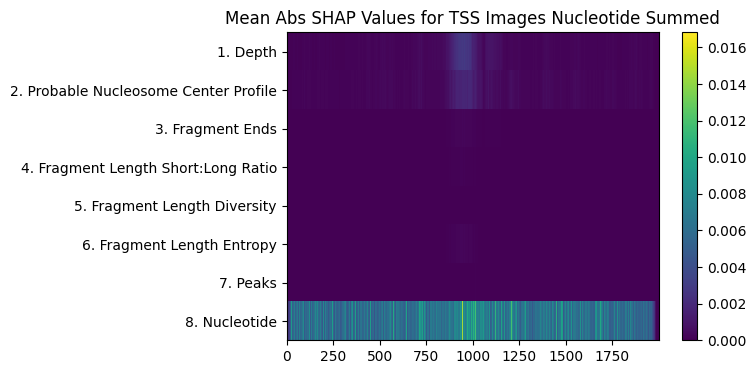

<Figure size 640x480 with 0 Axes>

<Figure size 600x400 with 0 Axes>

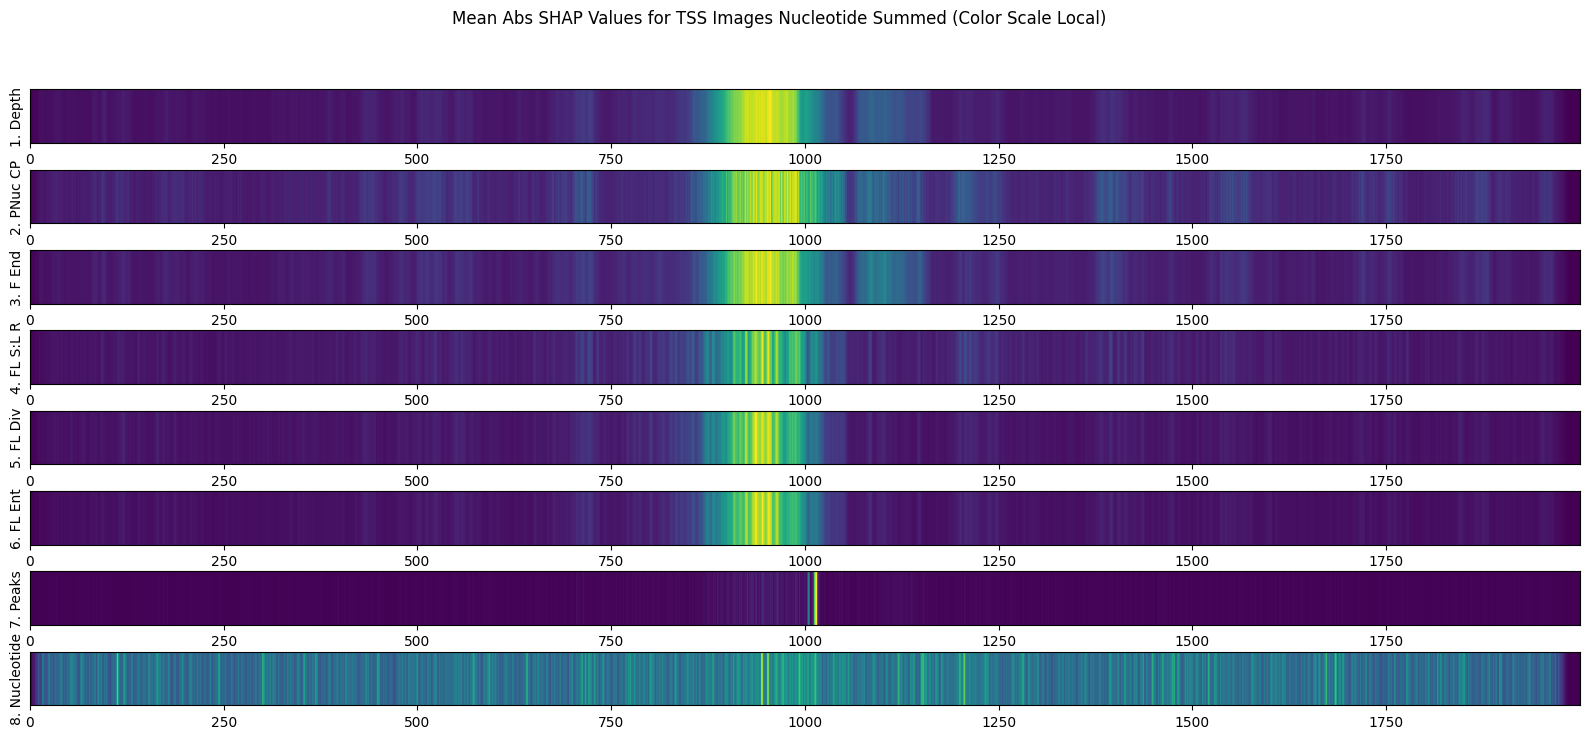

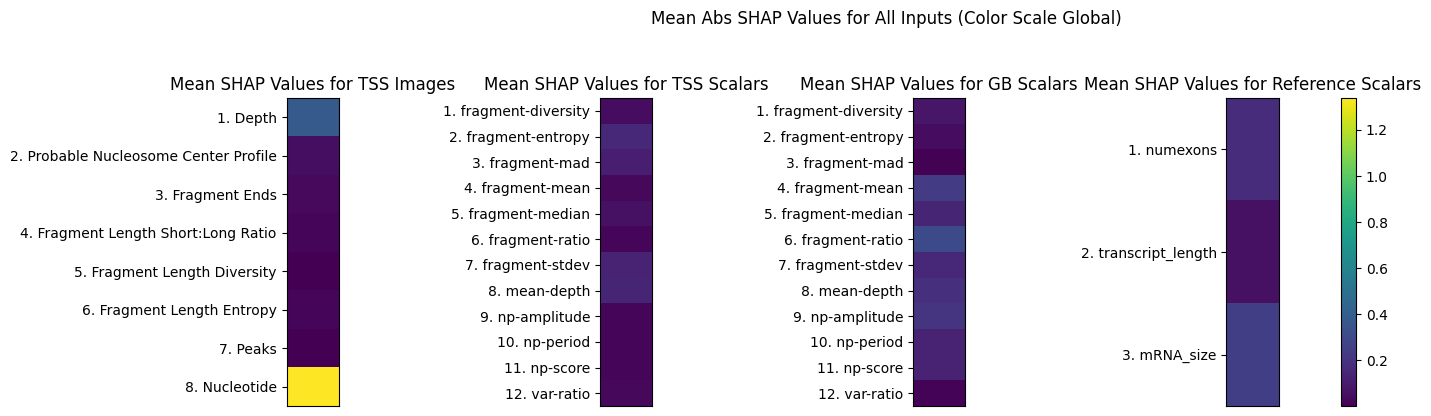

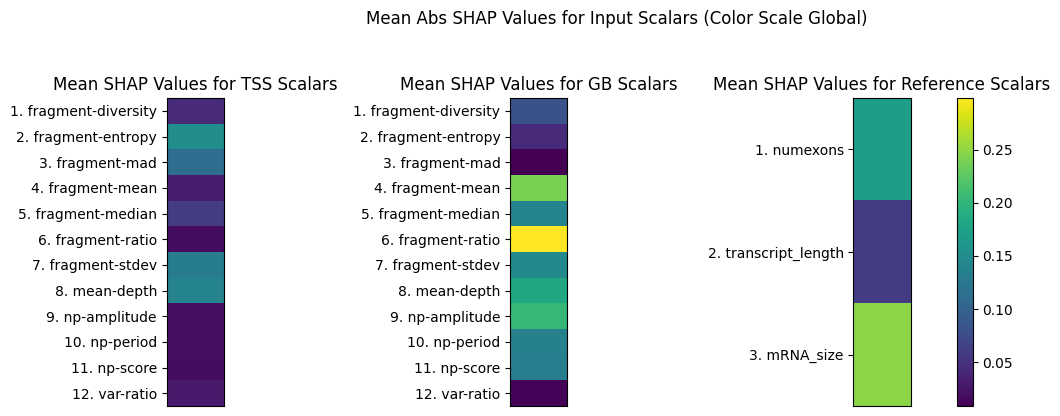

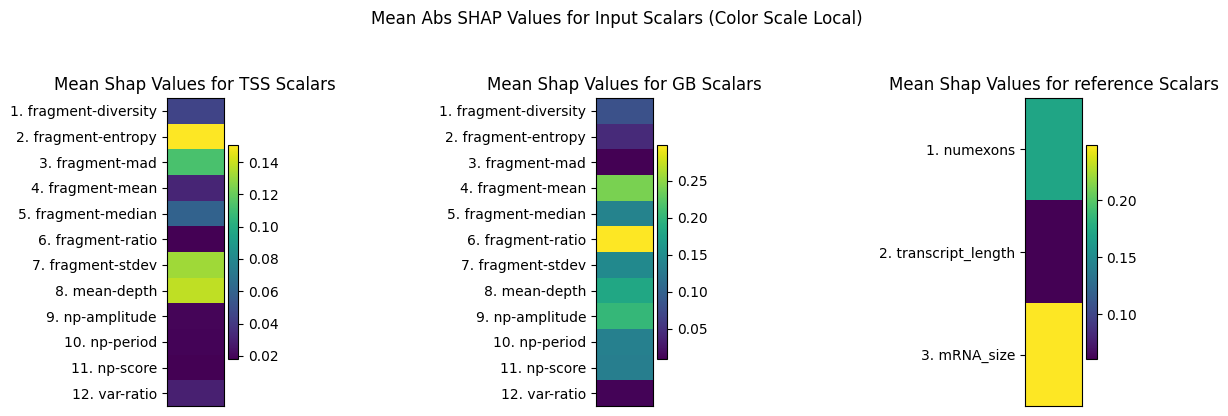

In [15]:
shap_analysis(best_model, input_data, background_size=5000, test_size=1000)#, save_filepath=save_filepath)

### Gradient Ascent

This function performs gradient ascent to a specfied expression level on a specified number of samples from a given dataset. 
Additionally, the user can adjust all the training parameters as they see fit, and which portions of the input they want to freeze.
We visualize:

1. Gradient Ascent Training Curves
2. Pre and Post Gradient Ascent Images
3. (Optionally) Pre and Post Gradient Ascent Scalars

Optionally, you can pass in a folder location to save the figures

In [11]:
input_lucap_down[0][0].shape

#test_flat = np.zeros_like(input_lucap_down[0][0])

first_input_lucap_down[0] = input_lucap_down[0][0]*0
first_input_lucap_down

[array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], dtype=float32),
 array([-1.5859271 , -1.670804  , -1.0418835 ,  0.66925454,  0.5939882 ,
        -0.38185003, -0.33094046, 29.636375  , -0.5628822 ,  0.449486  ,
         0.07365449, -1.2352123 ], dtype=float32),
 array([ 0.05615017,  0.3483654 , -0.68506056,  0.8448825 ,  0.7034265 ,
        -0.86356086, -0.05266523, 30.180748  , -1.0062983 , -0.8619232 ,
         1.7222618 , -1.8053128 ], dtype=float32),
 array([-0.8207934 , -0.44343254, -0.64684165], dtype=float32)]

In [7]:
zeroed_signal_lucap = input_lucap_down.copy()

In [10]:
zeroed_signal_lucap[0] = input_lucap_down[0]*0

In [ ]:
save_filepath = '/fh/fast/ha_g/user/anetzley/interpretation/interpretation_results/lucap_down_to_up'
gradient_output_data = gradient_ascent(zeroed_signal_lucap, best_model, 
                                       label = 10,
                                       num_trials = 50,
                                       iterations=100, #Optional
                                       step_size=5e-2, #Optional
                                       only_signal = True)
                                       #save_filepath = save_filepath)

In [21]:
losses_list, outputs_list, original_data, updated_data = gradient_output_data

<Figure size 640x480 with 0 Axes>

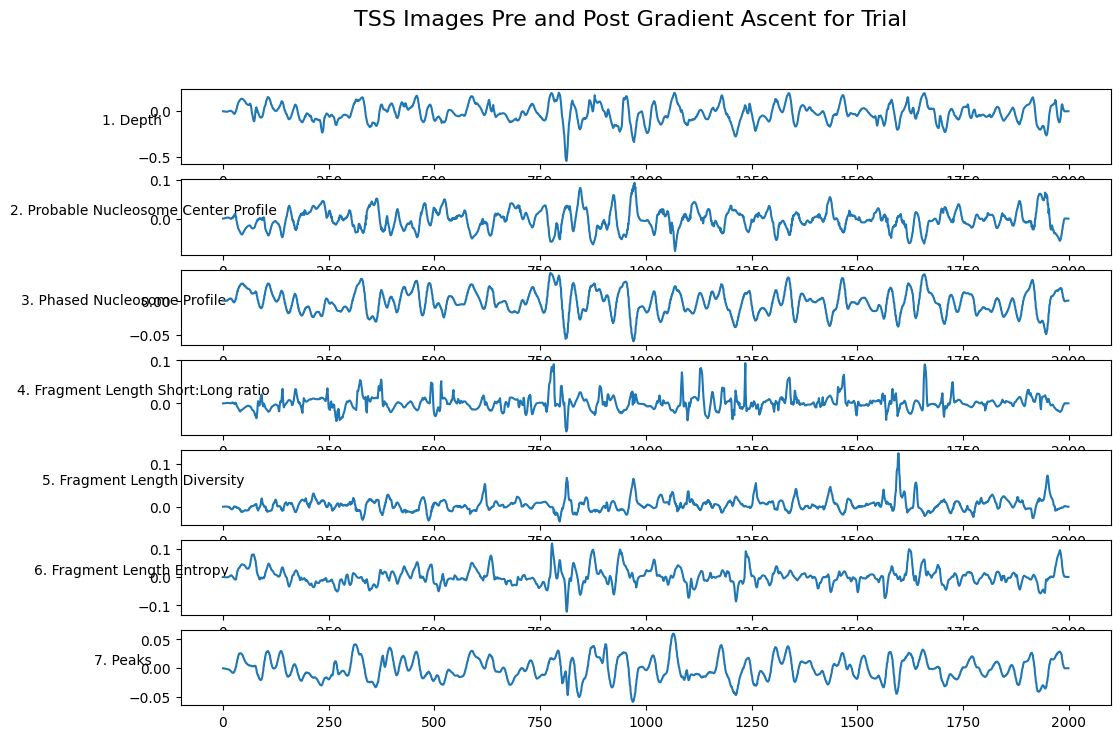

In [23]:
up_signals = []
for up_img in updated_data:
    up_signals.append((up_img[0]))

up_signals = np.array(up_signals)

avg_up_signals = np.squeeze(np.mean(up_signals, axis=0))

plt.clf()
cols = ['1. Depth', '2. Probable Nucleosome Center Profile', '3. Phased Nucleosome Profile', '4. Fragment Length Short:Long ratio', '5. Fragment Length Diversity', '6. Fragment Length Entropy', '7. Peaks']
  
fig, axs = plt.subplots(len(cols), 1, figsize=(12, 8))
for i in range(len(cols)):
    axs[i].plot(avg_up_signals[:, i])
    axs[i].set_ylabel(cols[i], rotation=0)
    
#plt.subplots_adjust(left=0.5)
fig.suptitle(f'TSS Images Pre and Post Gradient Ascent for Trial', fontsize=16)
fig.show()

1/1 [==============================] - 0s 417ms/step


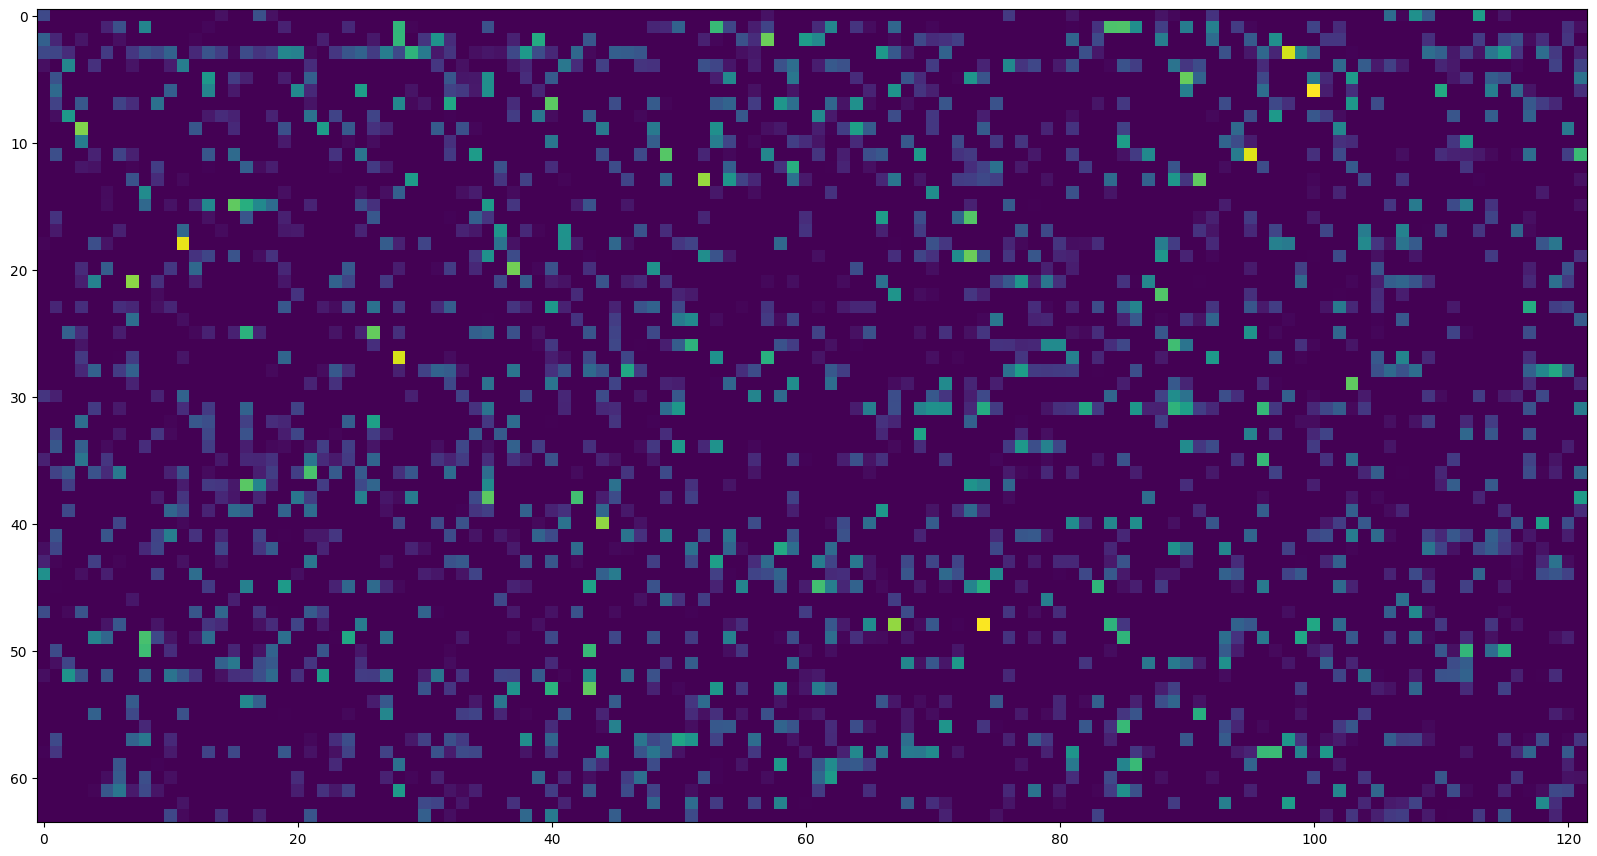

1/1 [==============================] - 0s 425ms/step


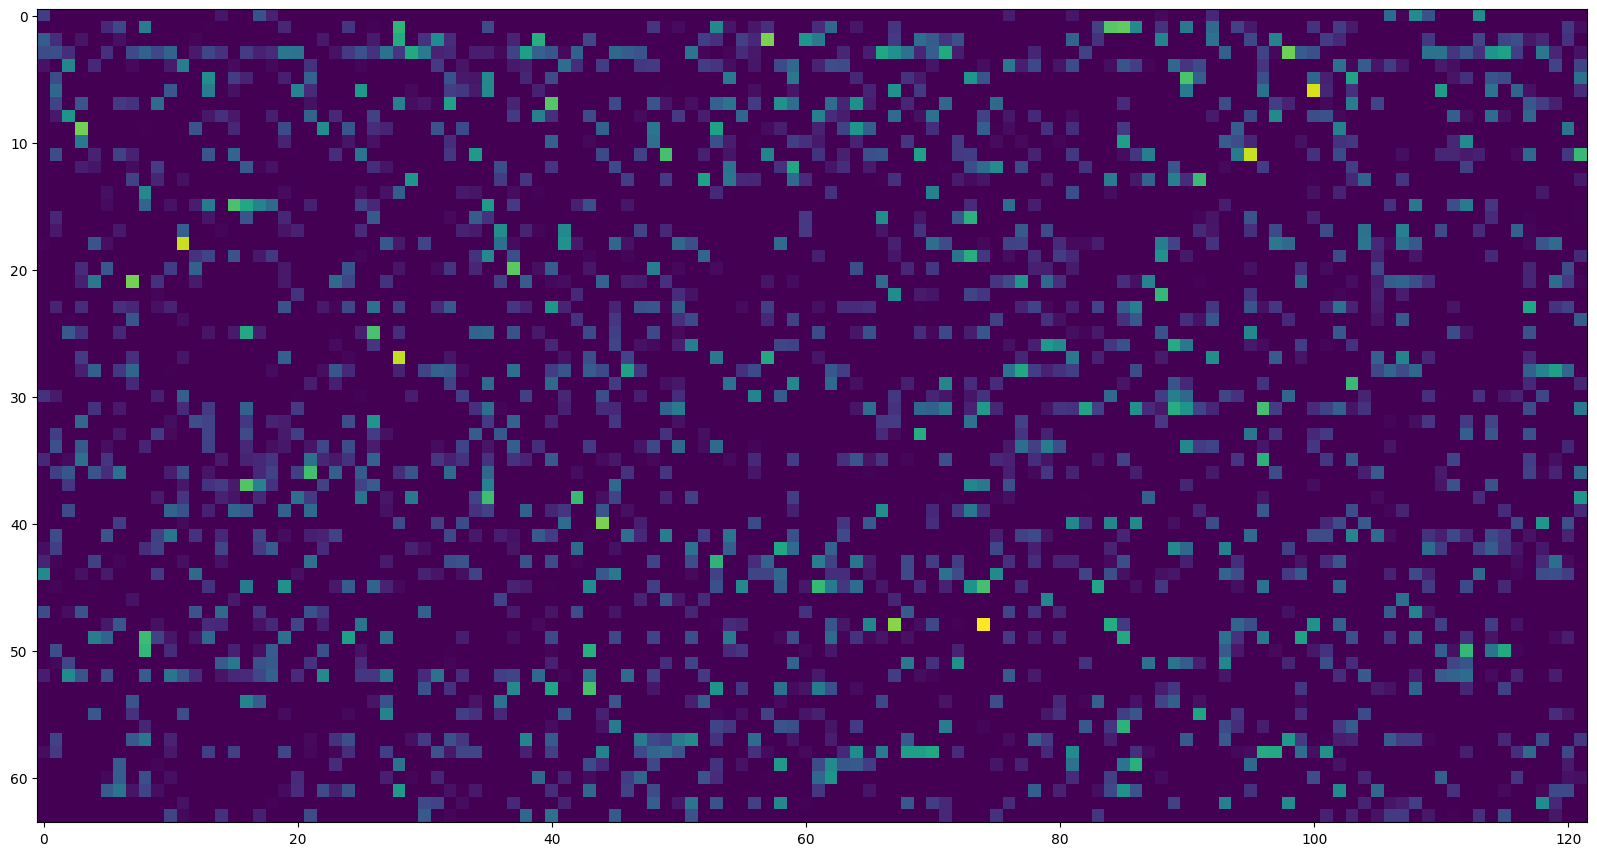

1/1 [==============================] - 0s 370ms/step


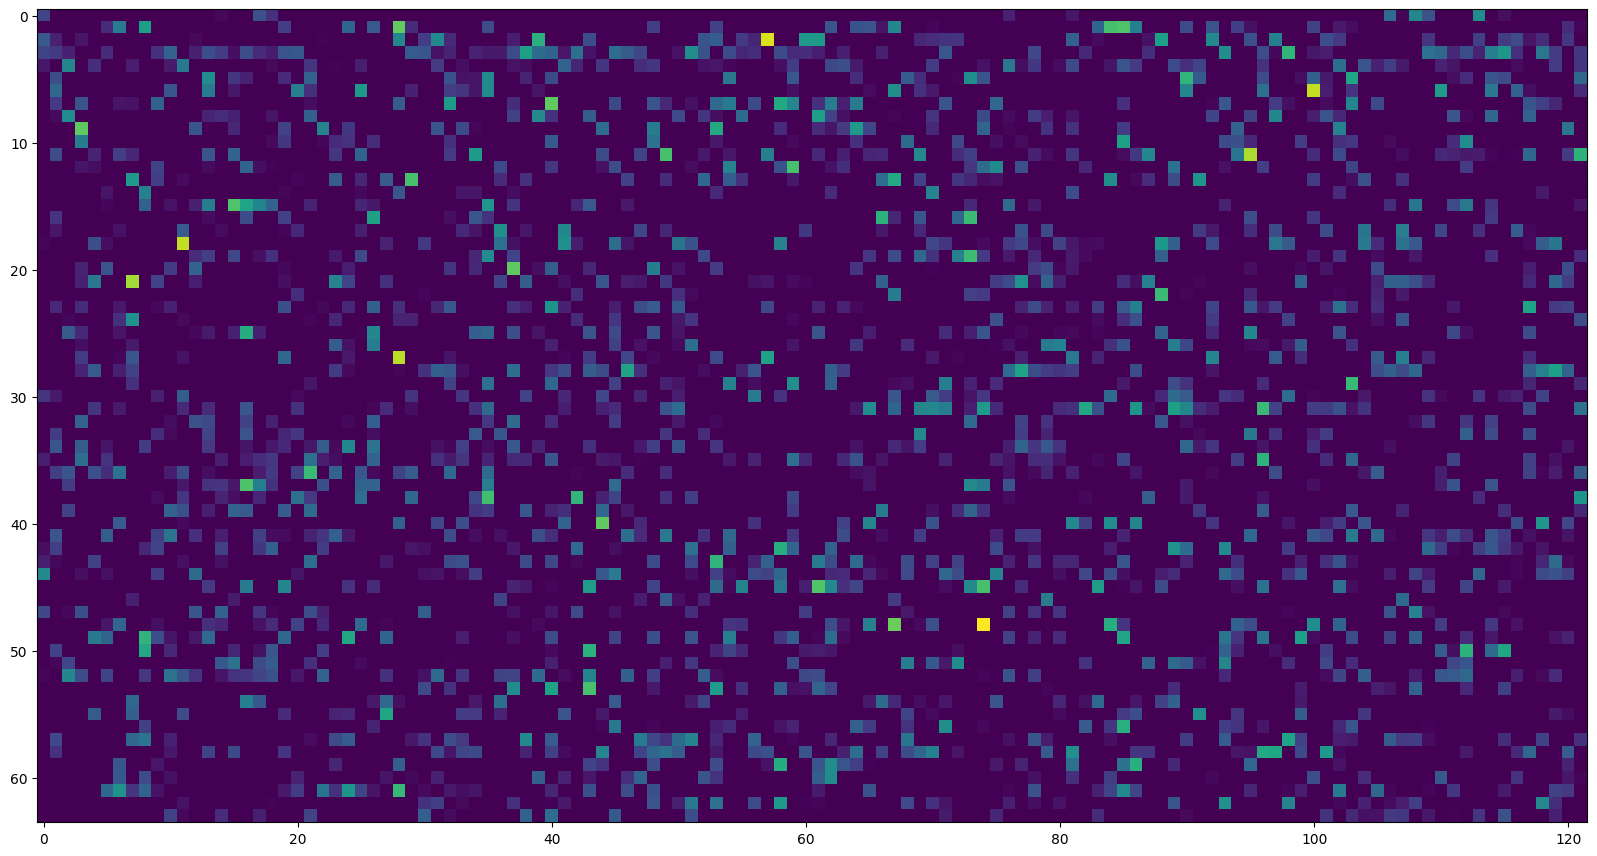

1/1 [==============================] - 0s 410ms/step


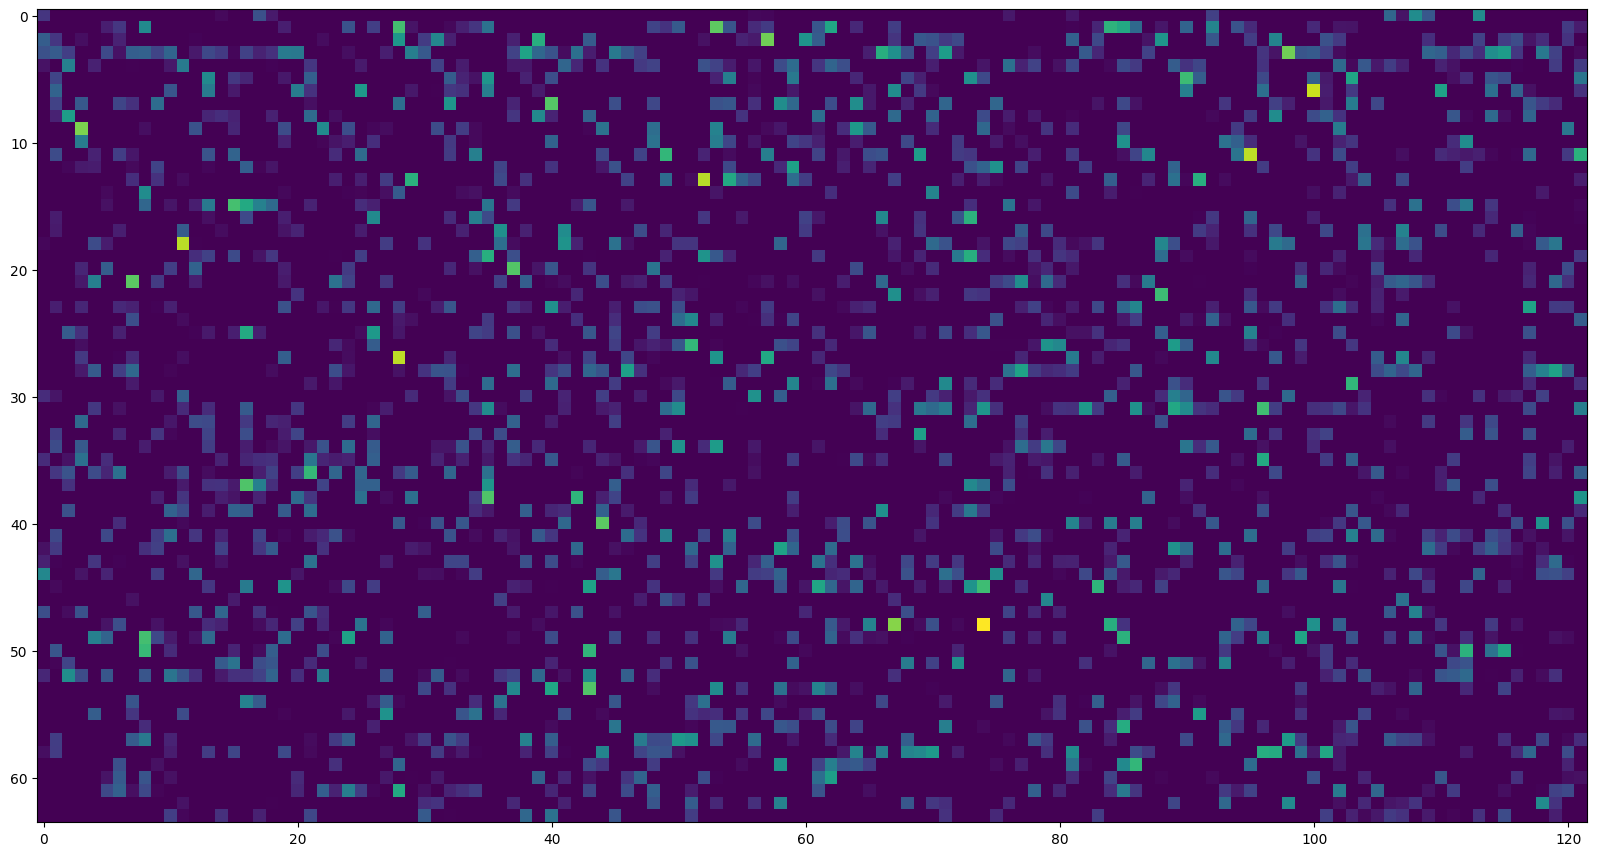

1/1 [==============================] - 0s 424ms/step


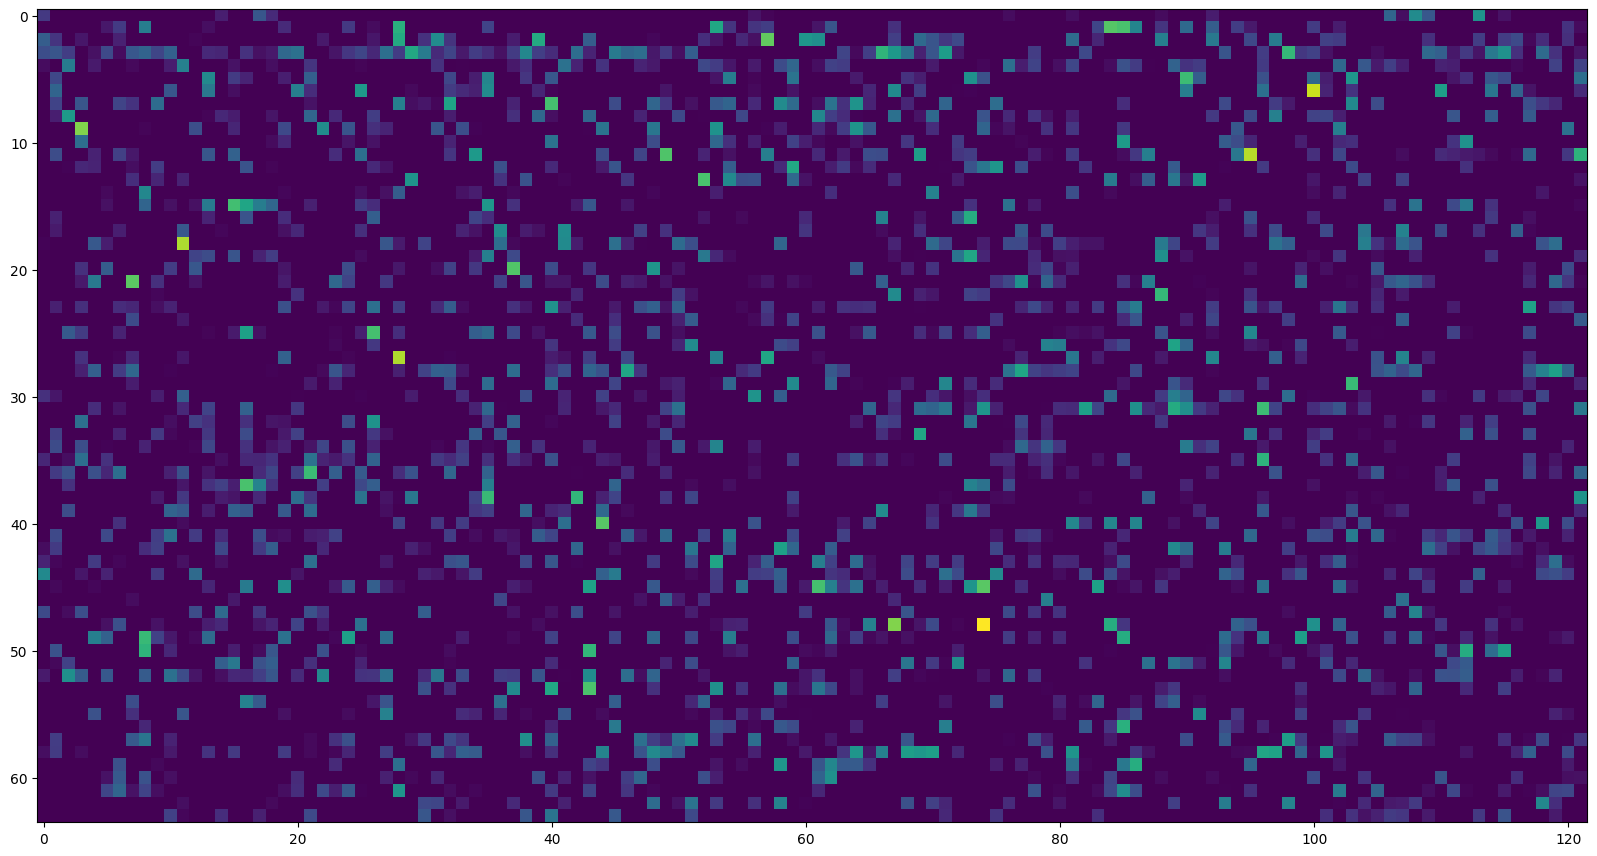

1/1 [==============================] - 0s 373ms/step


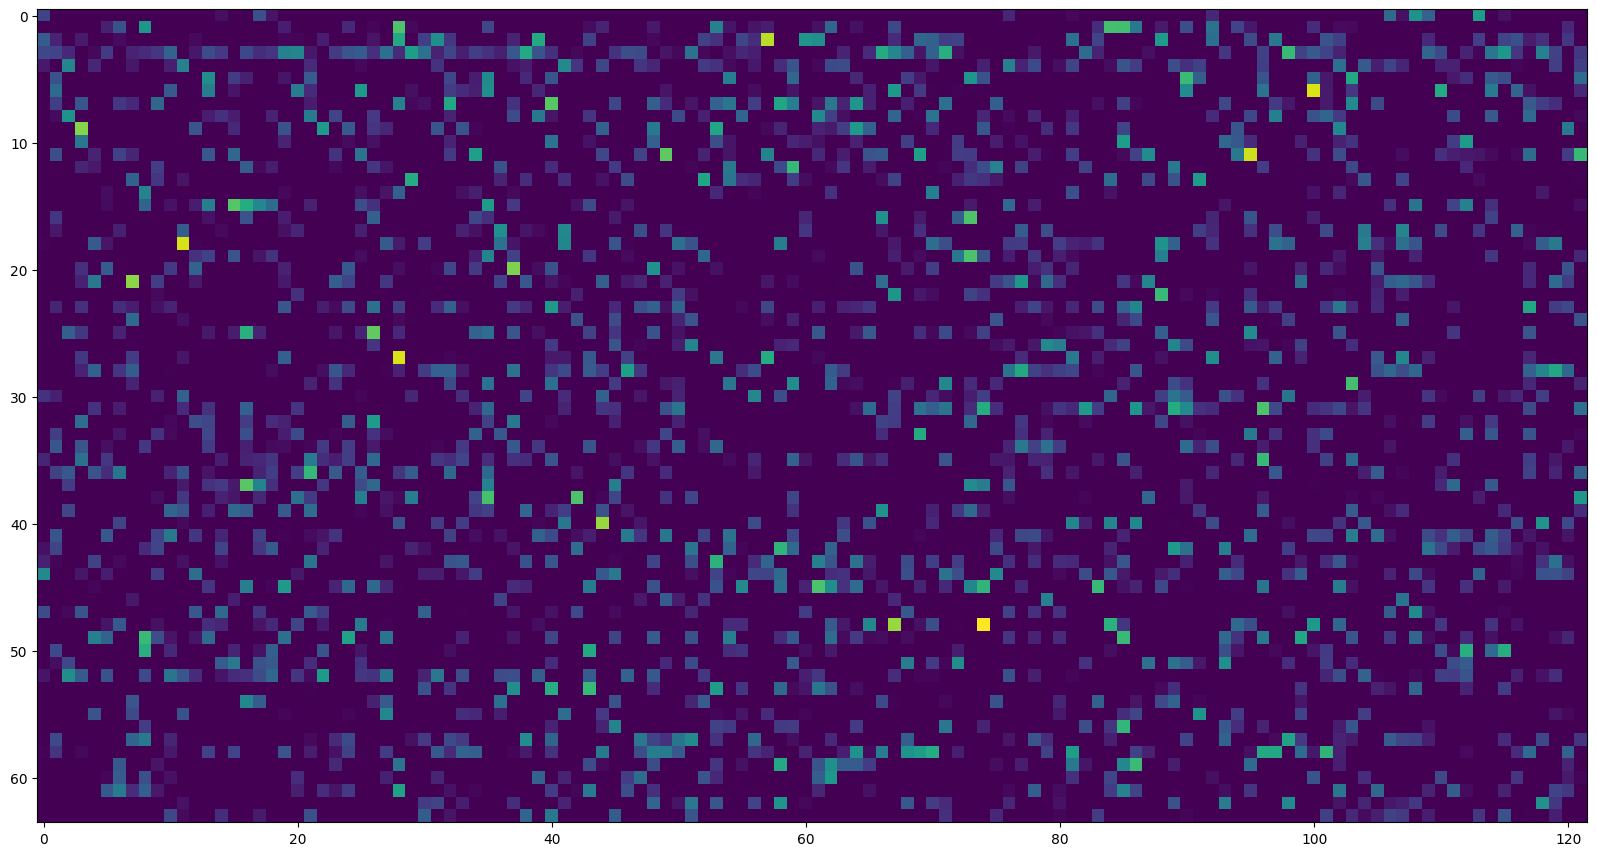

In [70]:
# Extract model at subset
int_outs = []
for i in range(6):

    input_AR_single = subsample(input_AR, sample_size = 1, seed=i)
    intermediate_model = keras.models.Model(inputs = best_model.input, outputs = best_model.get_layer('conv1d_21').output)
    intermediate_output = intermediate_model.predict(input_AR_single).squeeze()
    int_outs.append(intermediate_output.T)
    plt.figure(figsize=(20, 20))
    plt.imshow(intermediate_output.T, cmap='viridis', interpolation='nearest')
    #plt.gca().set_aspect(10)
    plt.show()

In [52]:
int_out = intermediate_output.T

In [67]:
int_outs[0] - int_outs[1]

array([[ 0.        ,  0.        , -8.127779  , ...,  7.3911133 ,
         8.869251  ,  1.231112  ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [-3.465191  , -3.899826  , -1.2980652 , ...,  1.5965691 ,
         1.1674423 ,  0.        ],
       ...,
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.0745697 ,  1.918251  , -3.2367706 , ..., -0.37737274,
         0.13013077,  0.8549118 ]], dtype=float32)